# Agrupando colores

Vamos a crear imagenes con una cantidad fija de colores

#### 1. Importa las librerias
Vamos a necesitar `KMeans` de `sklearn.cluster`, `imread` de `matplotlib.image`, `matplotlib.pyplot` y `numpy`


In [13]:
# importa las librerías
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import KMeans


#### 2. Lee las imagenes
Utiliza alguna foto que tengas en tu ordenador y leela con la función `imread`

Consejo: utiliza una imagen pequeña si no quieres tardar una eternidad en que se ejecute el kmeans

In [5]:
# usa imread
# comprueba las dimensiones del numpy array
imagen= plt.imread("mi_imagen.png")

Muestra la imagen para ver que se ha cargado bien

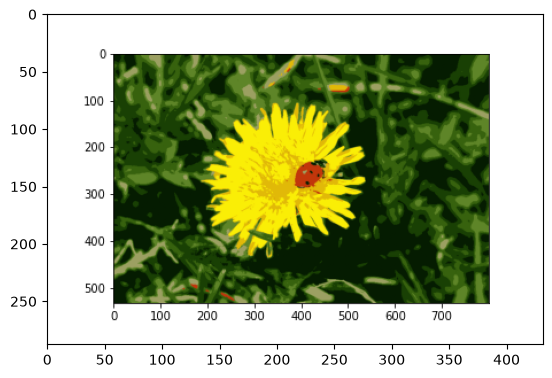

In [7]:
# usa imshow para mostrar la imagen
plt.imshow(imagen)

#### 3. Modifica la estructura de la imagen
Queremos que cada pixel sea una observación por lo que tenemos que transformar nuestra imagen de un vector de forma (alto, ancho, color) a (alto x ancho, color). Color será siempre 3, que son los tres canales de los colores.

Ej: (300, 400, 3) -> (120000, 3)

In [11]:
# modifica las dimensiones del numpy array
alto, ancho, canales = imagen.shape
imagen_plana = imagen.reshape(-1, 3)
print(imagen.shape,"->",imagen_plana.shape)

(288, 432, 4) -> (165888, 3)


#### 4. K-means
Haz un k-means con la imagen de entrada (Con la nueva forma que le hemos dado). K será el número de colores que quieras que tenga tu imagen de salida

In [32]:

# kmeans con 8 centroides por ejemplo, semilla 42 y 10 repeticiones del kmeans para elegir los centroides que acaban con la mejor inercia
# ajústalo a tus datos
from sklearn.cluster import KMeans
k= 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(imagen_plana)
colores_principales=kmeans.cluster_centers_
etiquetas =kmeans.labels_

print("Colores Enconttados:",colores_principales.astype(float),"\n Forma de las etiquetas:",etiquetas.shape)

Colores Enconttados: [[0.97817075 0.00490141 1.00001121]
 [0.13399932 0.25651336 0.0423404 ]
 [0.01736039 0.99707681 0.97562778]
 [0.99936861 0.97786278 0.96658146]
 [0.98948699 0.9754923  0.00688815]
 [0.27960676 0.05458444 0.99693984]
 [0.04277205 0.99752283 0.13938066]
 [0.98226893 0.15404034 0.26618508]] 
 Forma de las etiquetas: (165888,)


#### 5. Sustituye cada valor por su centroide

Una vez hemos entrenado el kmeans entre otros parametros de salida tiene `cluster_centers_` y `labels_`. Utilizas para crear una nueva imagen (recuerda que las imagenes simplemente son vectores numéricos) en la que cada pixel se sustituye por su centroide correspondiente.

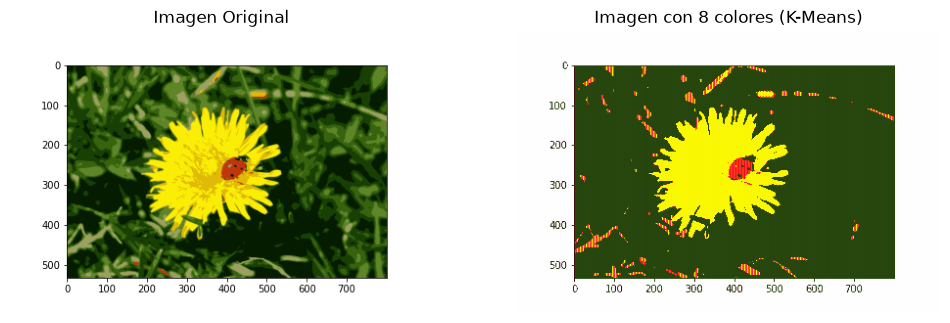

In [51]:
alto, ancho, canales = imagen.shape
img_original = plt.imread('mi_imagen.png')

centroides = kmeans.cluster_centers_
imagen_final = centroides[kmeans.labels_].reshape(alto, ancho, canales)

imagen_final = np.clip(imagen_final, 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img_original)
ax[0].set_title("Imagen Original")
ax[0].axis("off")

ax[1].imshow(imagen_final)
ax[1].set_title(f"Imagen con {k} colores (K-Means)")
ax[1].axis("off")
plt.show()

#### 6. Modifica la estructura de la imagen
Para trabajar con el k-means requeriamos que la imagen original fuese un solo vector, ahora como queremos volver a tener la imagen para volver mostrarla debemos hacer el proceso inverso a el paso 3. (Si has guardado la forma de la imagen original te será más facil hacer este paso)

In [59]:
imagen_cuantizada = kmeans.cluster_centers_[kmeans.labels_].reshape(alto, ancho, 3)
imagen_cuantizada = np.clip(imagen_cuantizada, 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(imagen)
ax[0].set_title("Imagen Original")
ax[0].axis("off")

ax[1].imshow(imagen_cuantizada)
ax[1].set_title(f"Imagen con {k} colores (K-Means)")
ax[1].axis("off")
plt.show()

ValueError: cannot reshape array of size 497664 into shape (288,432,3)

#### 7. Imprime y guarda en tu ordenador la imagen resultante

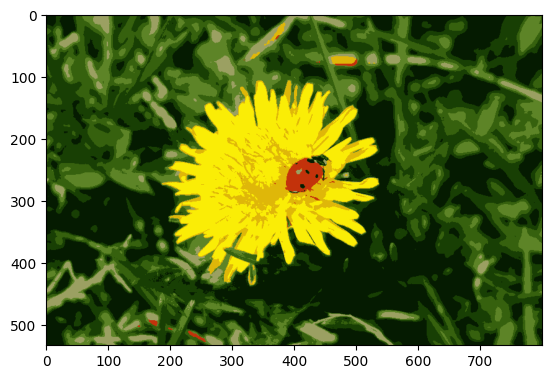

In [ ]:
# muestra la imagen modificada

#### 8. Crea una función
Crea una función que tenga como argumentos de entrada una imagen, el numero de colores que quieres que tenga, y si se quiere guardar o mostrar por pantalla

In [ ]:

        
        
# crea una función que dada una imagen, una cantidad de colores y si se quiere guardar la imagen modificada o solo mostrarla, que siga esos pasos